# Visualisation des instances (VRPLIB)

Ce notebook sert à **voir** une instance : tu écris son nom (par exemple `"C101"`) et il affiche quatre graphiques.

## Comment l'utiliser
1. Installe les bibliothèques : `pip install vrplib numpy matplotlib jupyter`.
2. Décompresse le zip `VRPLIB-main.zip` à côté de ce notebook. Le dossier des fichiers est `VRPLIB-main/tests/data`. Si tu l'as mis ailleurs, change la variable `DATA_DIR` dans la première cellule.
3. Exécute les cellules de code, puis lance `plot_instance("C101")` avec le nom que tu veux.

Le nom est reconnu sans tenir compte des majuscules : `"c101"` et `"C101"` fonctionnent. La commande `liste_instances()` affiche tous les noms disponibles.

## Les quatre graphiques
| Graphique | Ce qu'il montre |
|---|---|
| **Carte** (en haut à gauche) | la position des clients et du dépôt (carré rouge). La **taille** d'un point est la demande du client. La **couleur** est l'heure d'ouverture de sa fenêtre (instances Solomon) ou sa demande (instances X, sans fenêtres). |
| **Meilleure solution connue** (en haut à droite) | les routes de la solution de référence lue dans le fichier `.sol`, une couleur par camion. **Les flèches indiquent le sens de parcours** : le camion part du dépôt, suit les flèches, puis revient au dépôt. |
| **Fenêtres de temps** (en bas à gauche) | une barre horizontale par client, de son ouverture à sa fermeture, triées par heure d'ouverture. Les lignes rouges sont l'ouverture et la fermeture du dépôt. Pour les instances sans fenêtres : l'histogramme des demandes. |
| **Largeur des fenêtres** (en bas à droite) | combien de temps chaque client est disponible. Pour les instances sans fenêtres : le remplissage de chaque camion dans la solution de référence, en % de la capacité. |

Pour retirer les flèches : `plot_instance("C101", fleches=False)`.

In [ ]:
# Cellule de configuration
from pathlib import Path
from math import ceil
import numpy as np
import matplotlib.pyplot as plt
import vrplib

DATA_DIR = "VRPLIB-main/tests/data"        # dossier tests/data du zip décompressé
EXTENSIONS = {".txt", ".vrp", ".vrptw"}    # extensions des fichiers d'instances

In [2]:
def _index(data_dir=DATA_DIR):
    # {nom en minuscules : [chemins]} ; les instances présentes en double sont regroupées.
    idx = {}
    for p in Path(data_dir).rglob("*"):
        if p.is_file() and p.suffix.lower() in EXTENSIONS:
            idx.setdefault(p.stem.lower(), []).append(p)
    return idx


def liste_instances(filtre=""):
    # Affiche les noms d'instances disponibles (filtre = texte contenu dans le nom).
    noms = sorted(p[0].stem for k, p in _index().items() if filtre.lower() in k)
    print(len(noms), "instances :", ", ".join(noms))


def _charger(nom):
    idx = _index()
    if nom.lower() not in idx:
        print(f"Instance '{nom}' introuvable dans {DATA_DIR}. Essayez liste_instances().")
        return None
    # si l'instance existe en plusieurs exemplaires, on préfère celui qui a un fichier .sol
    chemins = sorted(idx[nom.lower()], key=lambda p: not p.with_suffix(".sol").exists())
    path = chemins[0]
    texte = path.read_text(errors="ignore")[:3000].upper()
    fmt = "solomon" if "CUSTOMER" in texte else "vrplib"       # format Solomon ou format VRPLIB
    inst = vrplib.read_instance(str(path), instance_format=fmt, compute_edge_weights=False)
    sol = vrplib.read_solution(str(path.with_suffix(".sol"))) if path.with_suffix(".sol").exists() else None
    return path, inst, sol


def plot_instance(nom, save=False, out_dir="figures", show=True, fleches=True):
    # Affiche quatre graphiques pour l'instance `nom` (ex. "C101", "X-n101-k25").
    # fleches=True : ajoute une flèche sur chaque trajet pour montrer le sens de parcours.
    chargee = _charger(nom)
    if chargee is None:
        return
    path, inst, sol = chargee
    d = np.asarray(inst["demand"], dtype=float)
    n = len(d) - 1
    Q, K = inst.get("capacity"), inst.get("vehicles")
    xy = inst.get("node_coord")
    tw = inst.get("time_window")
    routes = sol["routes"] if sol else None

    # ---- résumé texte
    print(f"{path.stem} : {n} clients | capacité Q = {Q} | camions max K = {K} | "
          f"demande totale = {d.sum():.0f} | camions min (capacité) = {ceil(d.sum() / Q)}")
    if tw is not None:
        w = tw[1:, 1] - tw[1:, 0]
        print(f"fenêtres : largeur min/moy/max = {w.min():.0f} / {w.mean():.0f} / {w.max():.0f} | "
              f"horizon du dépôt = {tw[0, 1]:.0f}")
    if sol:
        print(f"meilleure solution connue : coût = {sol['cost']} avec {len(routes)} routes")
    else:
        print("pas de fichier .sol pour cette instance")
    if xy is None:
        print("Cette instance n'a pas de coordonnées (distances données par matrice) : "
              "pas de carte possible, seuls les histogrammes sont tracés.")

    fig, axes = plt.subplots(2, 2, figsize=(15, 11))
    ax_map, ax_sol, ax_c, ax_d = axes.ravel()
    gros = n <= 150
    cmap_routes = plt.get_cmap("tab20")

    # ---- (a) carte des clients
    if xy is not None:
        couleur = tw[1:, 0] if tw is not None else d[1:]
        etiquette = "ouverture de la fenêtre $e_i$" if tw is not None else "demande $q_i$"
        taille = (150 if gros else 40) * (0.2 + 0.8 * d[1:] / max(d[1:].max(), 1))
        sc = ax_map.scatter(xy[1:, 0], xy[1:, 1], c=couleur, s=taille, cmap="viridis",
                            edgecolor="k", linewidth=0.3)
        ax_map.scatter(*xy[0], marker="s", s=130, c="red", edgecolor="k", zorder=5, label="dépôt")
        fig.colorbar(sc, ax=ax_map, label=etiquette, fraction=0.046)
        ax_map.set_title("Carte : couleur = " + etiquette + ", taille = demande")
        ax_map.set_aspect("equal"); ax_map.legend()
    else:
        ax_map.axis("off")
        ax_map.text(0.5, 0.5, "pas de coordonnées", ha="center")

    # ---- (b) meilleure solution connue
    if xy is not None and routes:
        for i, r in enumerate(routes):
            chemin = [0] + list(r) + [0]
            couleur = cmap_routes(i % 20)
            ax_sol.plot(xy[chemin, 0], xy[chemin, 1], "-", color=couleur, lw=1.4 if gros else 0.7)
            if fleches:                                   # une pointe de flèche au milieu de chaque trajet
                fonce = tuple(0.5 * c for c in couleur[:3])
                for a, b in zip(chemin[:-1], chemin[1:]):
                    p, q = xy[a], xy[b]
                    ax_sol.annotate("", xy=p + 0.56 * (q - p), xytext=p + 0.44 * (q - p),
                                    arrowprops=dict(arrowstyle="-|>", color=fonce, lw=0,
                                                    mutation_scale=17 if gros else 7,
                                                    shrinkA=0, shrinkB=0))
        ax_sol.scatter(xy[1:, 0], xy[1:, 1], s=8, c="k", zorder=3)
        ax_sol.scatter(*xy[0], marker="s", s=130, c="red", edgecolor="k", zorder=5)
        ax_sol.set_title(f"Meilleure solution connue : coût {sol['cost']}, {len(routes)} routes"
                         + ("\n(flèches = sens de parcours)" if fleches else ""))
        ax_sol.set_aspect("equal")
    elif routes:
        ax_sol.axis("off")
        ax_sol.text(0.5, 0.5, f"solution connue : coût {sol['cost']}, {len(routes)} routes\n"
                    "(non dessinable : pas de coordonnées)", ha="center")
    else:
        ax_sol.axis("off")
        ax_sol.text(0.5, 0.5, "pas de solution de référence\ndans les fichiers", ha="center")

    # ---- (c) fenêtres de temps, ou histogramme des demandes
    if tw is not None:
        ordre = np.argsort(tw[1:, 0])
        for rang, i in enumerate(ordre):
            ax_c.hlines(rang, tw[1 + i, 0], tw[1 + i, 1], lw=2.5 if gros else 0.8, color="tab:blue")
        ax_c.axvline(tw[0, 0], color="red", ls="--", label="ouverture / fermeture du dépôt")
        ax_c.axvline(tw[0, 1], color="red", ls="--")
        ax_c.set_xlabel("temps"); ax_c.set_ylabel("clients triés par ouverture")
        ax_c.set_title("Fenêtres de temps $[e_i, l_i]$ de chaque client"); ax_c.legend()
    else:
        ax_c.hist(d[1:], bins=25, color="tab:blue", edgecolor="k")
        ax_c.set_xlabel("demande $q_i$"); ax_c.set_ylabel("nombre de clients")
        ax_c.set_title("Histogramme des demandes")

    # ---- (d) largeur des fenêtres, ou remplissage des camions
    if tw is not None:
        ax_d.hist(w, bins=20, color="tab:orange", edgecolor="k")
        ax_d.axvline(np.median(w), color="k", ls="--", label=f"médiane = {np.median(w):.0f}")
        ax_d.set_xlabel("largeur de fenêtre $l_i - e_i$"); ax_d.set_ylabel("nombre de clients")
        ax_d.set_title("Largeur des fenêtres de temps"); ax_d.legend()
    elif routes:
        taux = sorted((100 * d[list(r)].sum() / Q for r in routes), reverse=True)
        ax_d.bar(range(len(taux)), taux, color="tab:green", edgecolor="k", lw=0.3)
        ax_d.axhline(100, color="red", ls="--", label="capacité")
        ax_d.set_xlabel("routes triées"); ax_d.set_ylabel("remplissage (% de Q)")
        ax_d.set_title("Remplissage des camions dans la meilleure solution"); ax_d.legend()
    else:
        ax_d.axis("off")

    fig.suptitle(f"Instance {path.stem}", fontsize=16)
    fig.tight_layout()
    if save:
        Path(out_dir).mkdir(exist_ok=True)
        fig.savefig(Path(out_dir) / f"{path.stem}.png", dpi=130, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)


def plot_all(out_dir="figures", filtre=""):
    # Enregistre une image PNG par instance (sans les afficher) dans out_dir.
    noms = sorted(p[0].stem for k, p in _index().items() if filtre.lower() in k)
    erreurs = []
    for nom in noms:
        try:
            plot_instance(nom, save=True, out_dir=out_dir, show=False)
        except Exception as e:          # une instance au format inhabituel ne doit pas tout arrêter
            erreurs.append((nom, str(e)[:80]))
    print(f"{len(noms) - len(erreurs)} images enregistrées dans '{out_dir}', {len(erreurs)} erreurs")
    for nom, msg in erreurs:
        print(" -", nom, ":", msg)

## Liste des instances disponibles

In [3]:
liste_instances()

187 instances : A-n32-k5, B-n31-k5, Bre-1, C101, C101.100.10, C101.25.3, C101.50.5, C102, C102.100.10, C103, C104, C105, C106, C107, C108, C109, C1_10_1.1000.100, C1_2_1, C1_2_1.200.20, C1_4_1.400.40, C1_6_1.600.60, C1_8_1.800.80, C201, C202, C203, C204, C205, C206, C207, C208, CMT1, CMT6, D022-04g, E-n13-k4, F-n72-k4, Golden_1, Li_21, M-n101-k10, NoColonSpecification, ORTEC-VRPTW-ASYM-00c5356f-d1-n258-k12, ORTEC-n242-k12, P-n16-k8, R-E016-03m, R101, R102, R103, R104, R105, R106, R107, R108, R109, R110, R111, R112, R201, R202, R203, R204, R205, R206, R207, R208, R209, R210, R211, RC101, RC102, RC103, RC104, RC105, RC106, RC107, RC108, RC201, RC202, RC203, RC204, RC205, RC206, RC207, RC208, S-E016-03m, U-A-n32-k5, X-n1001-k43, X-n101-k25, X-n106-k14, X-n110-k13, X-n115-k10, X-n120-k6, X-n125-k30, X-n129-k18, X-n134-k13, X-n139-k10, X-n143-k7, X-n148-k46, X-n153-k22, X-n157-k13, X-n162-k11, X-n167-k10, X-n172-k51, X-n176-k26, X-n181-k23, X-n186-k15, X-n190-k8, X-n195-k51, X-n200-k36, X-n

## Exemple 1 : `C101` (clients groupés)

C101 : 100 clients | capacité Q = 200 | camions max K = 25 | demande totale = 1810 | camions min (capacité) = 10
fenêtres : largeur min/moy/max = 37 / 61 / 89 | horizon du dépôt = 1236
meilleure solution connue : coût = 827.3 avec 10 routes


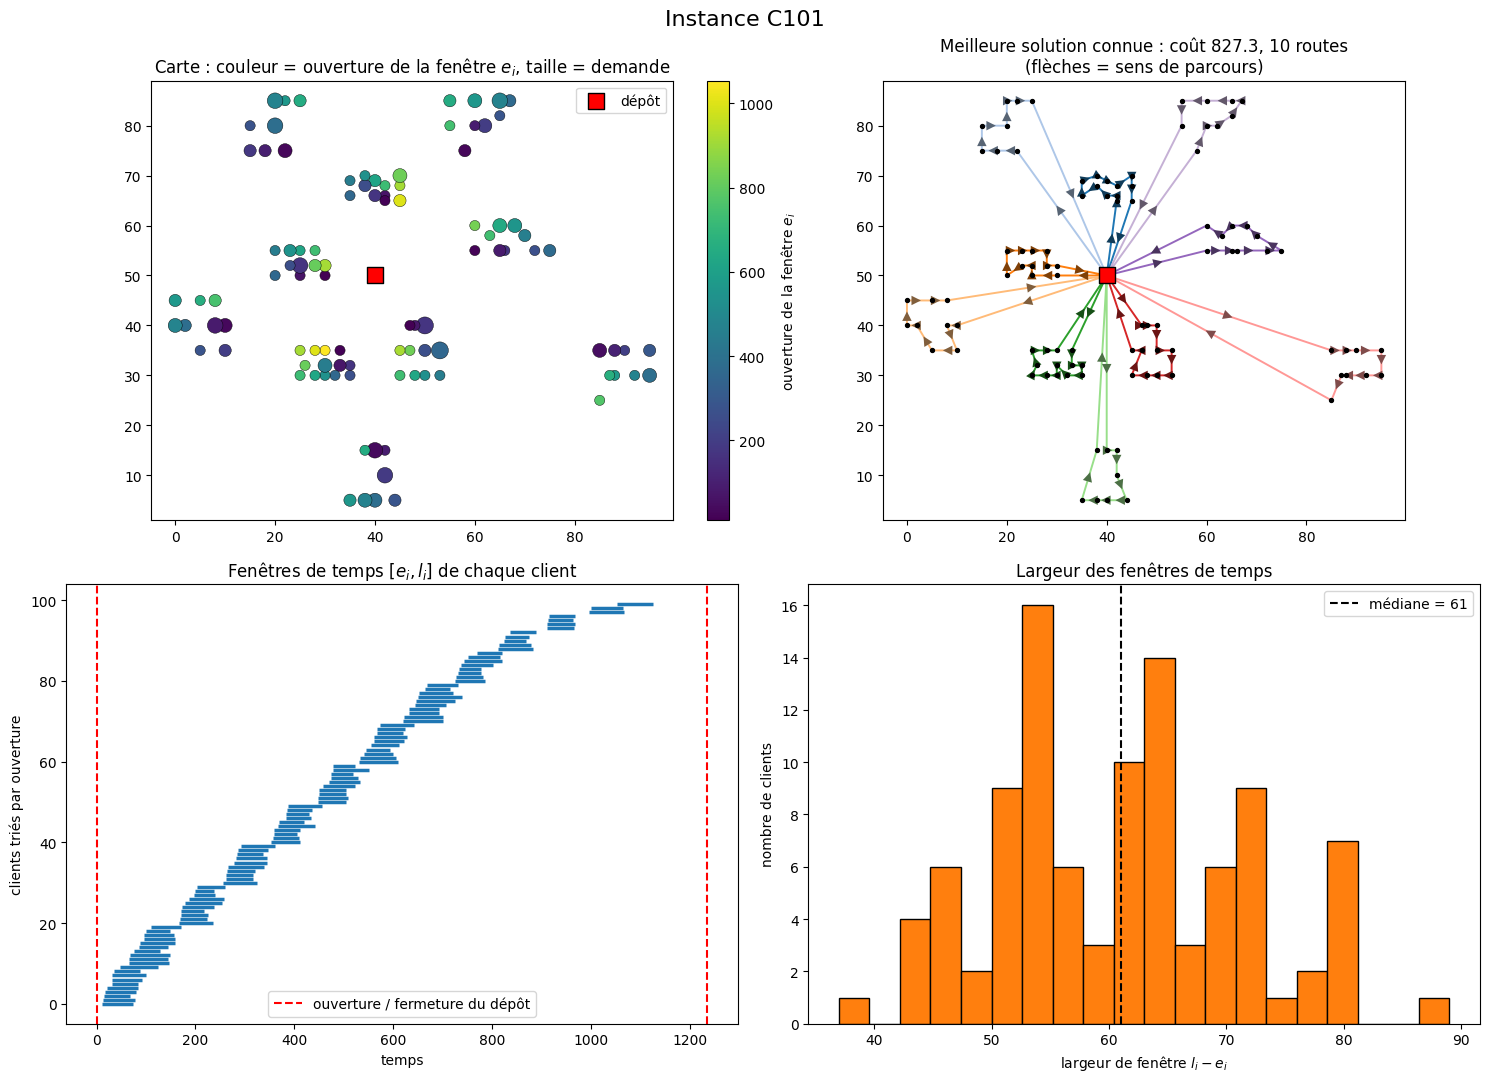

In [4]:
plot_instance("C101")

**Comment lire `C101`.**
- Les clients forment des **groupes** (*clustered*) : la carte montre une dizaine de petits paquets.
- La meilleure solution utilise **10 routes**, en gros une par groupe. Suis les flèches : chaque camion part du dépôt, fait le tour de son groupe, puis revient.
- Les fenêtres sont assez courtes (37 à 89 unités de temps) mais l'horizon du dépôt est long (1236) : les ouvertures s'étalent sur toute la journée.
- Ici, c'est surtout la **capacité** qui impose le nombre de camions : 1810 de demande pour des camions de 200, donc 10 au minimum.

**À propos du sens des flèches.** Dans une instance avec fenêtres de temps, le sens compte : parcourir la même route à l'envers peut la rendre infaisable (un client serait atteint après sa fermeture). Dans une instance sans fenêtres, la route inversée a exactement le même coût, donc le sens dessiné n'est qu'une convention du fichier.

## Exemple 2 : `R101` (clients au hasard, fenêtres très étroites)

R101 : 100 clients | capacité Q = 200 | camions max K = 25 | demande totale = 1458 | camions min (capacité) = 8
fenêtres : largeur min/moy/max = 10 / 10 / 10 | horizon du dépôt = 230
meilleure solution connue : coût = 1637.7 avec 20 routes


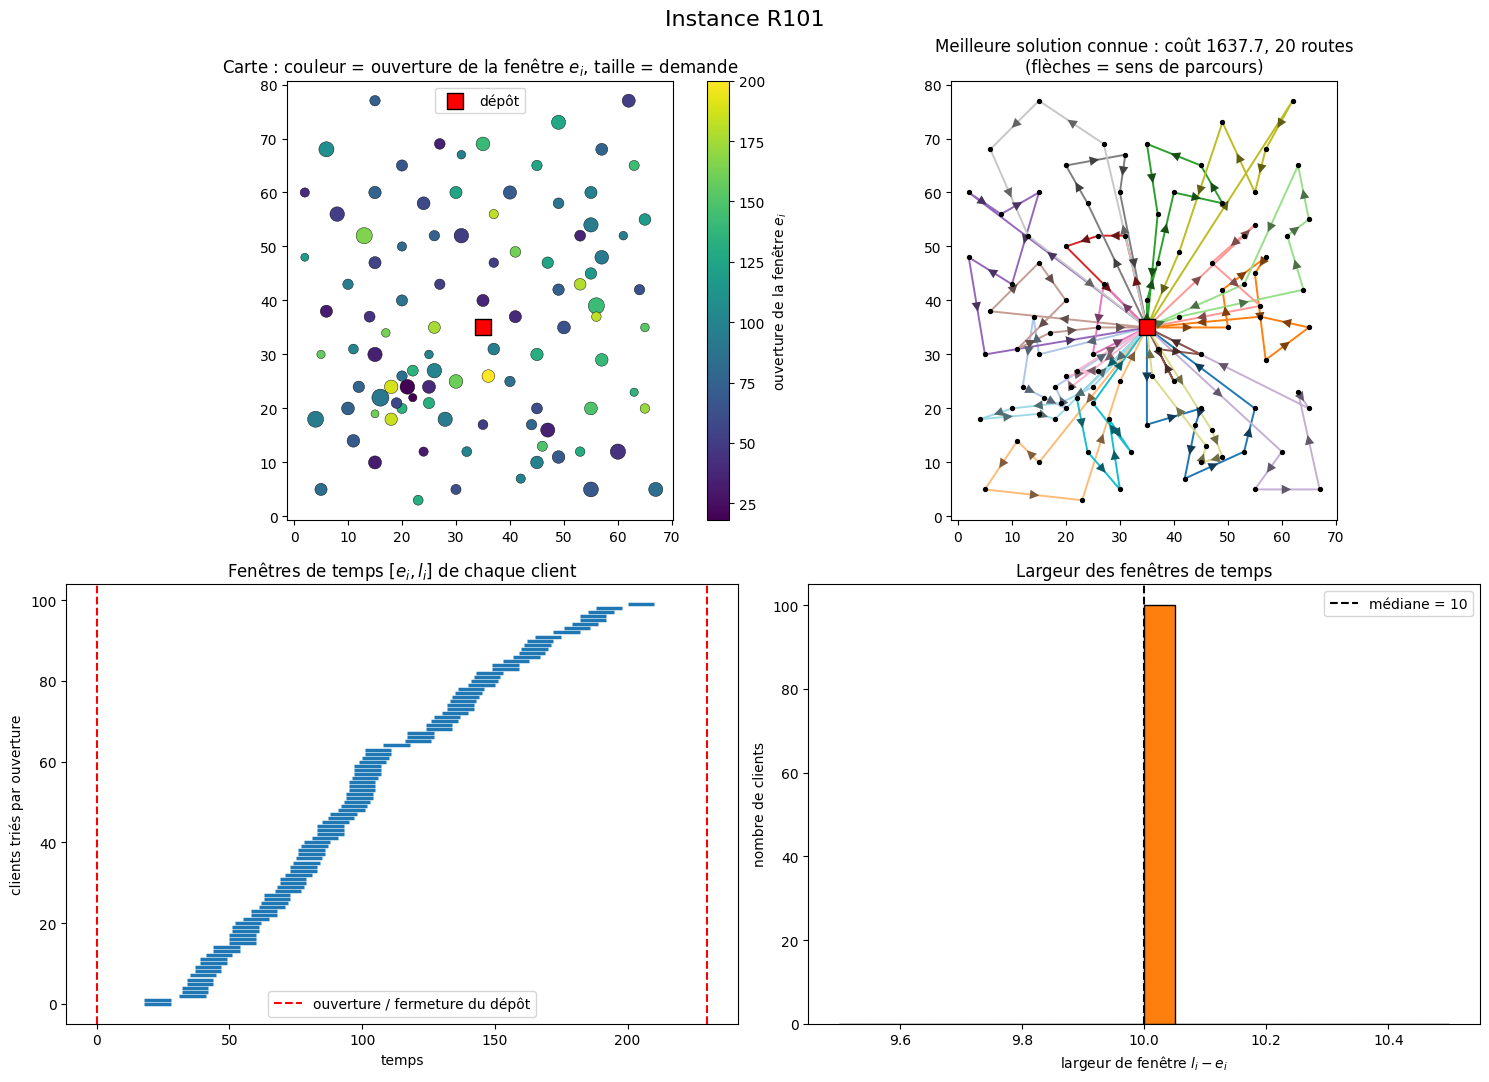

In [5]:
plot_instance("R101")

**Comment lire `R101`.**
- Les clients sont **répartis au hasard** : pas de groupes visibles.
- **Toutes les fenêtres font exactement 10** unités de temps, d'où un histogramme réduit à une seule barre.
- La meilleure solution utilise **20 routes** alors que la capacité n'en demanderait que 8 : ce sont les **fenêtres de temps** qui forcent à utiliser beaucoup de camions. Les routes sont courtes et entremêlées sur la carte.

## Exemple 3 : `RC101` (mélange des deux)

RC101 : 100 clients | capacité Q = 200 | camions max K = 25 | demande totale = 1724 | camions min (capacité) = 9
fenêtres : largeur min/moy/max = 30 / 30 / 30 | horizon du dépôt = 240
meilleure solution connue : coût = 1619.8 avec 15 routes


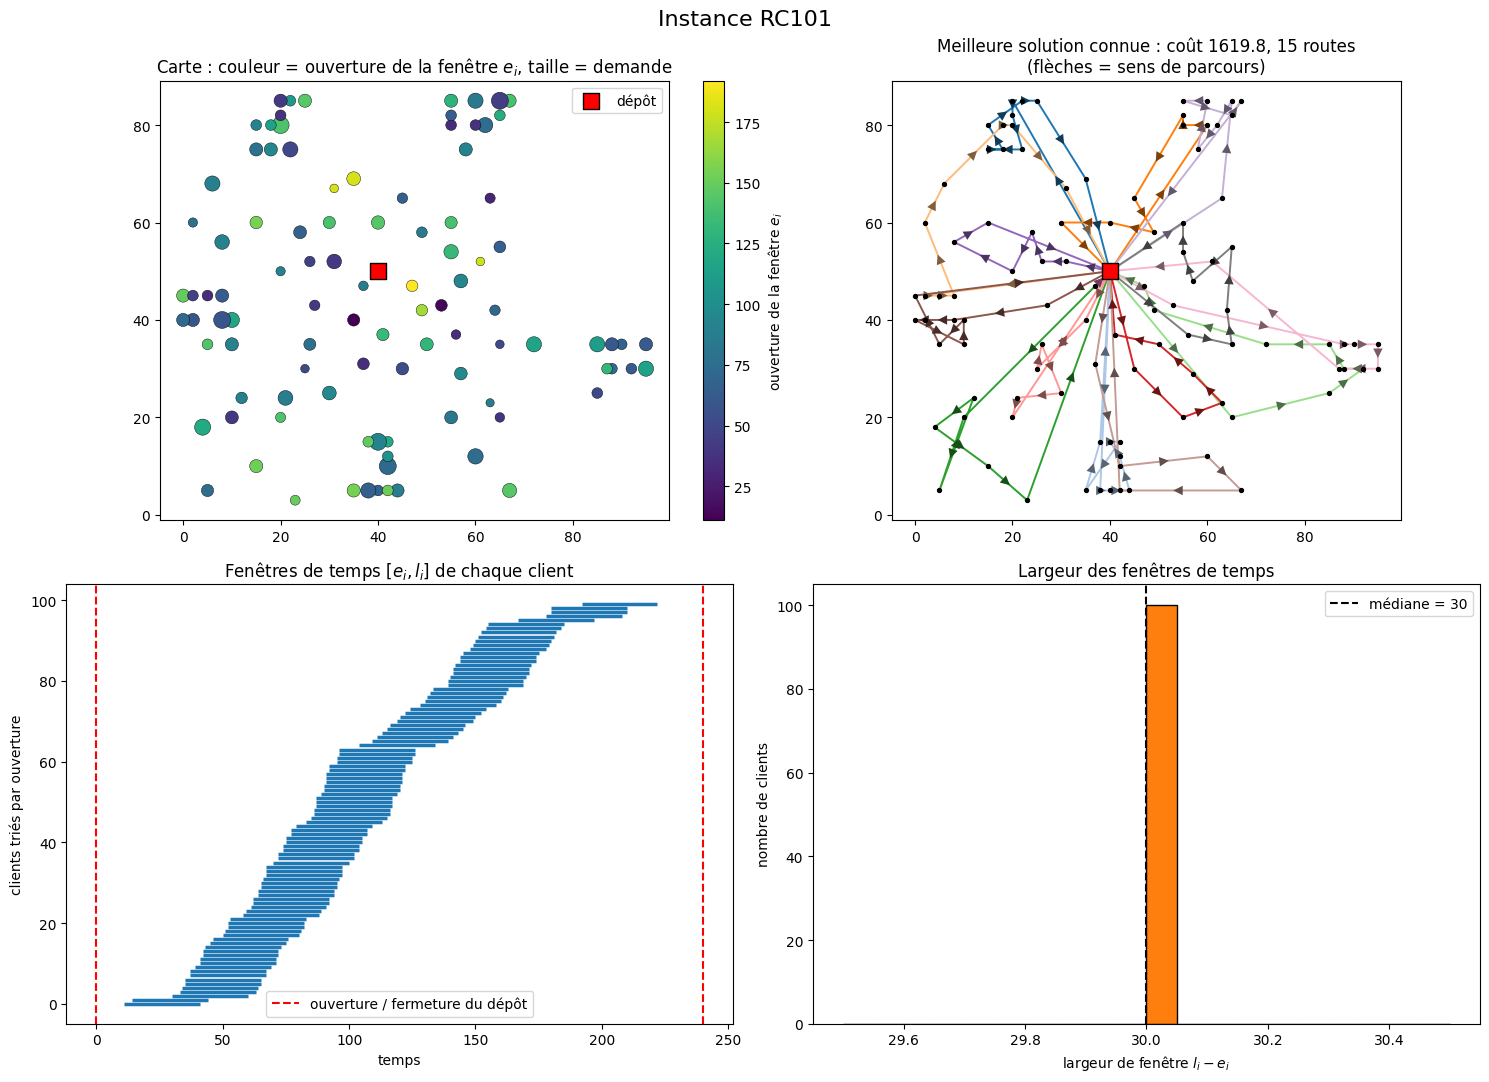

In [6]:
plot_instance("RC101")

**Comment lire `RC101`.** Une partie des clients est groupée et une autre dispersée. Toutes les fenêtres font 30 unités de temps (plus larges que dans `R101`), et la meilleure solution utilise 15 routes : entre `C101` (10) et `R101` (20).

## Exemple 4 : `X-n101-k25` (sans fenêtres de temps)

X-n101-k25 : 100 clients | capacité Q = 206 | camions max K = None | demande totale = 5147 | camions min (capacité) = 25
meilleure solution connue : coût = 27591 avec 26 routes


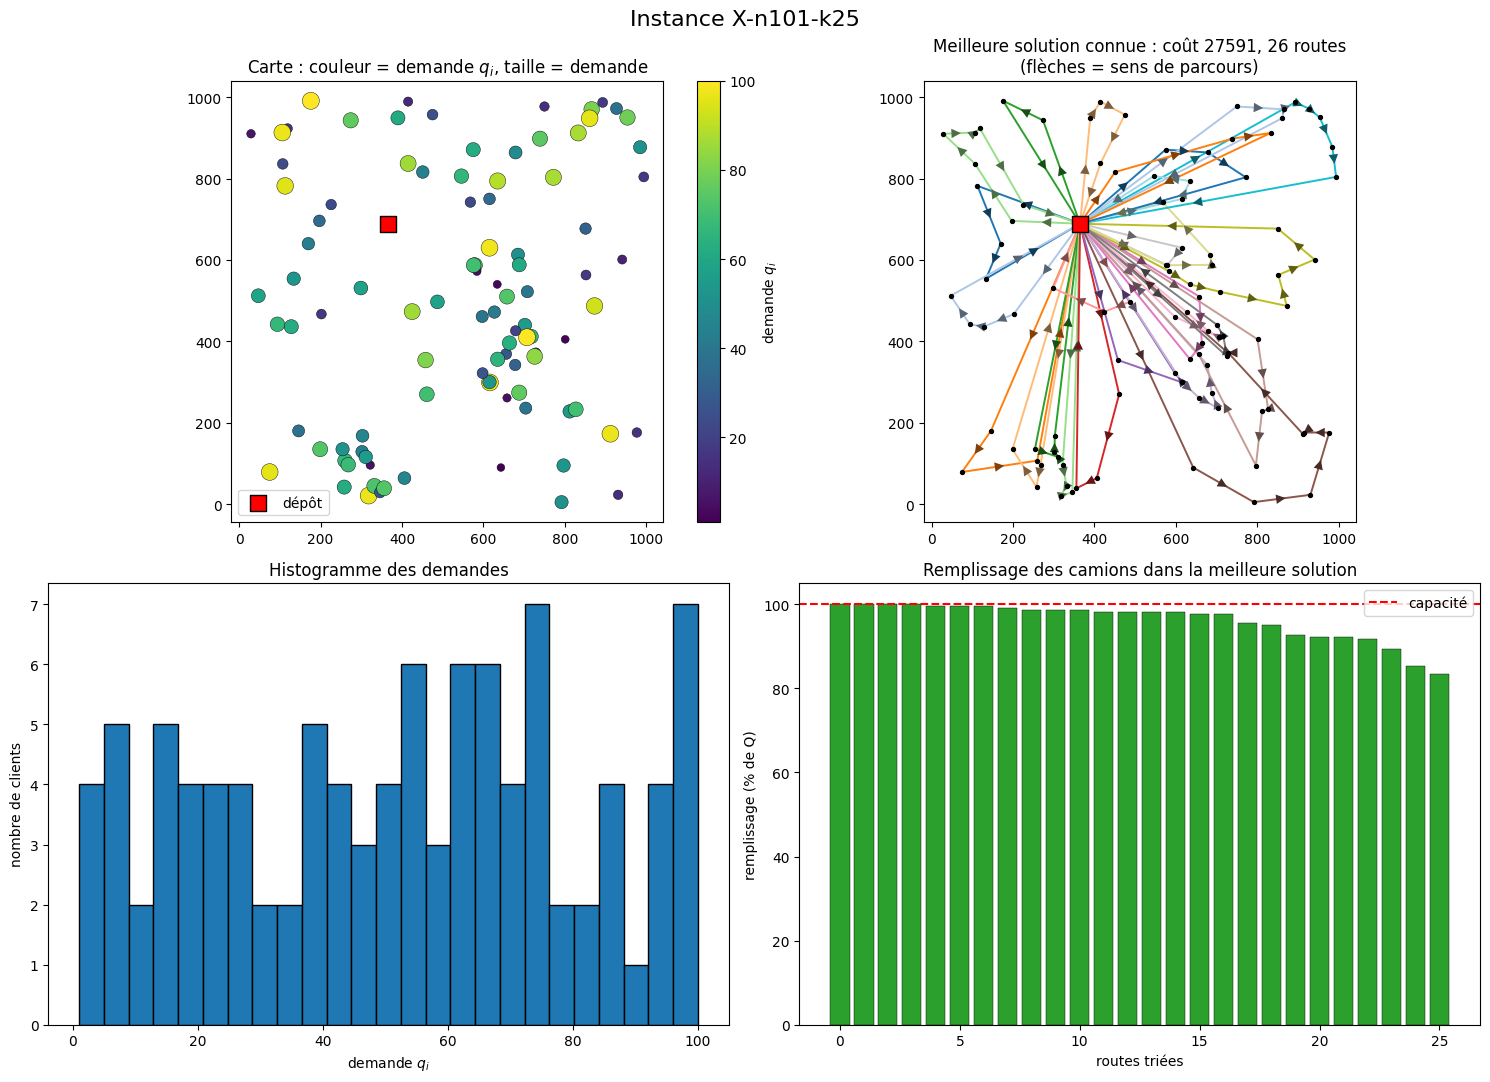

In [7]:
plot_instance("X-n101-k25")

**Comment lire `X-n101-k25`.**
- Il n'y a **pas de fenêtres de temps** : le graphique du bas à gauche est l'histogramme des demandes, et celui du bas à droite le remplissage des camions.
- Le `k25` du nom est un **minimum** : la meilleure solution connue utilise 26 routes.
- Quand les camions sont presque pleins (barres proches de 100 %), la capacité est la contrainte qui compte.

## Enregistrer les images
- `plot_instance("C101", save=True)` enregistre l'image dans le dossier `figures/`.
- `plot_all()` enregistre **une image par instance** (environ 2 minutes pour les 185 instances). Deux fichiers du dépôt VRPLIB ne sont pas de vraies instances (`empty` et `NoColonSpecification`, utilisés par les auteurs pour tester la bibliothèque) et sont signalés comme erreurs, c'est normal.
- `plot_all(filtre="X-n1")` ne traite que les instances dont le nom contient `X-n1`.

In [8]:
# Décommente la ligne suivante pour générer toutes les images (environ 2 minutes)
# plot_all()